# 11 – Nachtrag: Hält das Ergebnis, wenn das 10-cm-Netz länger lernt?

**Ziel.** Den länger gelernten Lauf `A_10cm_lang` (Notebook 07, Abschnitt 11) auf die Testblöcke anwenden und neben die erste Auswertung stellen.

**Warum.** Beim Lauf `A_10cm` war die beste Epoche die letzte. Dann ist nicht belegt, dass das Netz ausgelernt hat (`01b`, 7.4). Die Antwort auf die Leitfrage "5 cm gegen 10 cm" im Bild 2021 könnte davon abhängen. Der Auftraggeber hat am 27.11.2026 freigegeben, das zu prüfen.

**Das ist eine zweite Auswertung der Testblöcke.** Vorgesehen war eine einzige (`01b`, 8.1 K6). Darum gelten feste Regeln, die vor dem Rechnen aufgeschrieben wurden (`01b`, Abschnitt 11.2, N2):

| Regel | Inhalt |
| --- | --- |
| Was gilt? | Die **erste Auswertung** (Notebooks 08 bis 10) bleibt das Ergebnis des Pilots. Sie wird hier nicht verändert. |
| Was ist dieses Notebook? | Eine **Gegenprobe**: dieselben Schritte, dasselbe Bild, dieselben Testblöcke, nur das länger gelernte Netz. |
| Wann gilt die Aussage als bestätigt? | "5 cm zählt im Bild 2021 besser als 10 cm" gilt als bestätigt, wenn das 95-%-Intervall von $\bar D$ auch mit dem länger gelernten Netz die 0 nicht enthält. Sonst hängt die Aussage von der Lerndauer ab. |
| Wird danach noch etwas eingestellt? | Nein. |

**Damit nichts verwechselt wird**, rechnet das Notebook zuerst den ersten Lauf nach. Kommen dieselben Zahlen heraus wie in den Notebooks 08 bis 10, sind die Schritte hier dieselben wie dort. Erst dann kommt das neue Netz.

**Eingaben:** die Netze `A_10cm` und `A_10cm_lang` und ihre Schwellen (Notebook 07), `ergebnisse/zaehlung.csv` (Notebook 09: Ground Truth, amtliche Zahl und erste Auswertung je Testausschnitt), die gespeicherten Masken des ersten Laufs (Notebook 08), Kategorie je Pixel (Notebook 05), `platzmasse.json` (Notebook 03), `strassenraum.gpkg` (Notebook 04), das Luftbild 2021.
**Ausgaben:** `ergebnisse/masken/A_10cm_lang/`, `ergebnisse/nachtrag_zaehlung.csv`, `ergebnisse/nachtrag_auswertung.csv`, Abbildung `11_nachtrag.png`.

In [1]:
import json                        # Einstellungen, Schwellen und Platzmasse lesen
from pathlib import Path           # Pfade zusammensetzen

ROOT = Path.cwd().parent                             # Projektordner (eine Ebene über notebooks/)
ROH = ROOT / "daten" / "roh"                         # Rohdaten (werden nie verändert)
VERARB = ROOT / "daten" / "verarbeitet"              # abgeleitete Daten
ERG = ROOT / "ergebnisse"                            # Ergebnisse
ABB = ERG / "abbildungen"                            # Abbildungen

EINST = json.loads((ROOT / "einstellungen.json").read_text(encoding="utf-8"))   # Einstellungen früherer Notebooks
CRS, SEED, KACHEL_PX, VERSUCHE, CODE = EINST["CRS"], EINST["SEED"], EINST["KACHEL_PX"], EINST["VERSUCHE"], EINST["CODE"]
SCHWELLEN = json.loads((ERG / "schwellen.json").read_text(encoding="utf-8"))    # Schwelle je Lauf (Notebook 07, eingefroren)
MASSE = json.loads((VERARB / "platzmasse.json").read_text(encoding="utf-8"))    # Platzmasse aus Notebook 03

import numpy as np                 # Pixelraster, Rechnen und Zufall
import pandas as pd                # Tabellen
import geopandas as gpd            # Tabellen mit Geometrie
import matplotlib.pyplot as plt    # Abbildungen
import rasterio                    # Luftbilder lesen
from rasterio.merge import merge   # Ausschnitt aus mehreren Bilddateien zusammensetzen
from rasterio.features import shapes               # Raster zurück in Formen
from rasterio.transform import from_origin         # Lage eines Rasters festlegen
from shapely.geometry import shape                 # Form aus einer Beschreibung
import torch                       # neuronale Netze
from netz import GERAET, MITTEL, STREUUNG, lade_modell   # Bauplan und Laden des Netzes (Datei netz.py)

**Einstellungen dieses Schritts.** Es sind genau die Werte der Notebooks 08 bis 10. Hier wird nichts neu gewählt.

| Einstellung | Wert | Herkunft |
| --- | --- | --- |
| `RAND_PX`, `SCHRITT_PX` | 256 und 256 Pixel | Notebook 08: Rand um den Ausschnitt, Schritt der Fenster |
| `KACHEL_M`, `PIXEL_M` | 51,2 m und 0,10 m | Seitenlänge eines Ausschnitts; Pixelgrösse bei 10 cm |
| `ZIEHUNGEN` | 10'000 | Notebook 10: Wiederholungen des Bootstraps |

In [2]:
RAND_PX = 256
SCHRITT_PX = 256
KACHEL_M = 51.2
PIXEL_M = 0.10
ZIEHUNGEN = 10_000
ERST, LANG, FEIN = "A_10cm", "A_10cm_lang", "A_5cm"                  # erster Lauf, länger gelernter Lauf, 5-cm-Lauf zum Vergleich
print("Schwellen aus Notebook 07:", {lauf: SCHWELLEN[lauf]["schwelle"] for lauf in [ERST, LANG]})

Schwellen aus Notebook 07: {'A_10cm': 0.4, 'A_10cm_lang': 0.4}


## 1. Was vom ersten Lauf übernommen wird

Ground Truth und amtliche Zahl je Testausschnitt hängen nicht vom Netz ab. Sie stehen schon in `zaehlung.csv` (Notebook 09) und werden von dort gelesen, zusammen mit der ersten Auswertung der Läufe `A_10cm` und `A_5cm`.

Vorher: 548 Zeilen (4 Läufe × 137 Testausschnitte) → nachher: je eine Tabelle für `A_10cm` und `A_5cm`, eine Zeile je Testausschnitt.

In [3]:
zaehlung = pd.read_csv(ERG / "zaehlung.csv")                         # Notebook 09
aufteilung = pd.read_csv(VERARB / "aufteilung.csv")
test = aufteilung[aufteilung.gruppe == "testen"].set_index("kachel") # Testausschnitte, Kennung als Index
erst = zaehlung[zaehlung.lauf == ERST].set_index("kachel").loc[test.index]   # erste Auswertung bei 10 cm, in der Reihenfolge von test
fein = zaehlung[zaehlung.lauf == FEIN].set_index("kachel").loc[test.index]   # Lauf bei 5 cm
print(f"Vorher: {len(zaehlung)} Zeilen → nachher: {len(erst)} Testausschnitte in {test.block.nunique()} Blöcken")
erst[["wahr", "gezaehlt", "wahr_vergleich", "gezaehlt_vergleich", "amtlich"]].sum().to_frame("Summe A_10cm, erste Auswertung").T

Vorher: 548 Zeilen → nachher: 137 Testausschnitte in 15 Blöcken


,wahr,gezaehlt,wahr_vergleich,gezaehlt_vergleich,amtlich
"Summe A_10cm, erste Auswertung",708,626,360,336,354


## 2. Die Vorhersage, wie in Notebook 08

**Schritt 1: das Bild eines Testausschnitts lesen.** Der Rahmen mit Rand wird bei 5 cm gelesen; dann werden je 2 × 2 Pixel gemittelt. Das ergibt das 10-cm-Bild.

In [4]:
QUELLEN = [rasterio.open(pfad) for pfad in sorted((ROH / "orthofoto" / VERSUCHE["A"]["ordner"]).glob("*.tif"))]   # Luftbild Frühjahr 2021

def bild_mit_rand(ausschnitt):
    # Bild eines Testausschnitts bei 10 cm, samt Rand von 256 Pixeln (wie Notebook 08)
    rand_m = RAND_PX * PIXEL_M                                       # 25,6 m
    links, unten = ausschnitt.i * KACHEL_M - rand_m, ausschnitt.j * KACHEL_M - rand_m
    bild, _ = merge(QUELLEN, bounds=(links, unten, links + KACHEL_M + 2 * rand_m, unten + KACHEL_M + 2 * rand_m), res=0.05, indexes=[1, 2, 3])
    kanaele, hoehe, breite = bild.shape
    bloecke = bild.reshape(kanaele, hoehe // 2, 2, breite // 2, 2).astype("uint16")   # je 2 × 2 Pixel zusammenfassen
    return ((bloecke.sum(axis=(2, 4)) + 2) // 4).astype("uint8")                      # ihr Mittel, gerundet

print("Ein Bild mit Rand:", bild_mit_rand(test.iloc[0]).shape, "(Farben, Zeilen, Spalten)")

Ein Bild mit Rand: (3, 1024, 1024) (Farben, Zeilen, Spalten)


**Schritt 2: überlappende Fenster.** Das Netz sieht jeweils 512 × 512 Pixel. Die Fenster überlappen sich zur Hälfte; für jeden Pixel wird der Unterschied der Rohwerte (Parkfläche − keine) über alle Fenster gemittelt.

In [5]:
@torch.no_grad()                                                     # nur anwenden, nicht lernen
def unterschied_karte(modell, bild):
    # Mittlerer Unterschied der Rohwerte (Parkfläche − keine) je Pixel, über alle Fenster, die den Pixel enthalten
    _, hoehe, breite = bild.shape
    summe = np.zeros((hoehe, breite), np.float32)
    anzahl = np.zeros((hoehe, breite), np.float32)
    normiert = (torch.from_numpy(bild).float() / 255.0 - MITTEL) / STREUUNG      # wie beim Lernen (Notebook 07)
    for z in range(0, hoehe - KACHEL_PX + 1, SCHRITT_PX):            # Fenster von oben nach unten
        for s in range(0, breite - KACHEL_PX + 1, SCHRITT_PX):       # und von links nach rechts
            fenster = normiert[:, z:z + KACHEL_PX, s:s + KACHEL_PX].unsqueeze(0).to(GERAET)
            with torch.autocast(GERAET, dtype=torch.float16, enabled=GERAET == "cuda"):
                rohwerte = modell(fenster)[0].float()                # [2, 512, 512]
            summe[z:z + KACHEL_PX, s:s + KACHEL_PX] += (rohwerte[1] - rohwerte[0]).cpu().numpy()
            anzahl[z:z + KACHEL_PX, s:s + KACHEL_PX] += 1
    return summe / anzahl

**Schritt 3: alle Testausschnitte eines Laufs.** Gemeldet wird ein Pixel, wenn die Sicherheit über der Schwelle $\tau$ des Laufs liegt, also wenn der Unterschied grösser ist als $\ln\big(\tau / (1 - \tau)\big)$. Danach wird der Rand abgeschnitten.

In [6]:
def alle_masken(lauf):
    # Karte "Parkfläche gemeldet" (True/False) für jeden Testausschnitt, mit Netz und Schwelle dieses Laufs
    modell = lade_modell(lauf)                                       # bester Stand des Laufs (Notebook 07)
    grenze = np.log(SCHWELLEN[lauf]["schwelle"] / (1 - SCHWELLEN[lauf]["schwelle"]))   # Schwelle der Sicherheit, umgerechnet auf den Unterschied
    masken = {}
    for ausschnitt in test.itertuples():
        unterschied = unterschied_karte(modell, bild_mit_rand(ausschnitt))
        masken[ausschnitt.Index] = unterschied[RAND_PX:-RAND_PX, RAND_PX:-RAND_PX] > grenze
    del modell
    torch.cuda.empty_cache()                                         # Grafikspeicher freigeben
    return masken

**Kontrolle 1: Das erste Netz noch einmal.** Wir rechnen die Vorhersage des ersten Laufs `A_10cm` neu und vergleichen sie Pixel für Pixel mit den Masken, die Notebook 08 gespeichert hat. Das zeigt zweierlei: Die Schritte hier sind dieselben wie in Notebook 08, und die Vorhersage lässt sich wiederholen.

Vorher: gespeicherte Masken aus Notebook 08 → nachher: Zahl der Masken, die neu gerechnet gleich sind.

In [7]:
gespeichert = {kachel: np.load(ERG / "masken" / ERST / f"{kachel}.npz")["gemeldet"] for kachel in test.index}   # Masken aus Notebook 08
neu_gerechnet = alle_masken(ERST)
gleich = sum(np.array_equal(neu_gerechnet[kachel], gespeichert[kachel]) for kachel in test.index)              # Masken ohne jeden Unterschied
abweichend = sum(int((neu_gerechnet[kachel] != gespeichert[kachel]).sum()) for kachel in test.index)           # Pixel mit Unterschied
alle_pixel = sum(maske.size for maske in gespeichert.values())
print(f"Kontrolle 1: {gleich} von {len(test)} Masken sind Pixel für Pixel gleich | abweichende Pixel: {abweichend} von {alle_pixel}")

Kontrolle 1: 137 von 137 Masken sind Pixel für Pixel gleich | abweichende Pixel: 0 von 35913728


**Schritt 4: die Vorhersage des länger gelernten Netzes.** Dieselben Schritte mit dem Netz `A_10cm_lang` und seiner Schwelle. Die Masken werden gespeichert.

Vorher: Testausschnitte → nachher: eine Karte je Testausschnitt für `A_10cm_lang`.

In [8]:
masken_lang = alle_masken(LANG)
(ERG / "masken" / LANG).mkdir(parents=True, exist_ok=True)
for kachel, maske in masken_lang.items():
    np.savez_compressed(ERG / "masken" / LANG / f"{kachel}.npz", gemeldet=maske)
anteil_erst = np.mean([maske.mean() for maske in gespeichert.values()])        # mittlerer Anteil gemeldeter Pixel, erster Lauf
anteil_lang = np.mean([maske.mean() for maske in masken_lang.values()])        # ... länger gelernter Lauf
print(f"Mittlerer Anteil gemeldeter Pixel: {anteil_erst:.4f} (A_10cm) | {anteil_lang:.4f} (A_10cm_lang)")

Mittlerer Anteil gemeldeter Pixel: 0.0212 (A_10cm) | 0.0211 (A_10cm_lang)


## 3. Die Zählung, wie in Notebook 09

**Schritt 1: zwei Hilfen.** `im_vergleichsraum` prüft, ob ein Punkt im Strassenraum und im Gebiet liegt. `flaechen_tabelle` zerlegt eine Maske in zusammenhängende Flächen und gibt jeder ihre mittlere Tiefe, ihre Klasse und ihre Platz-Äquivalente (`01b`, Abschnitt 11, E7). Beide Funktionen sind aus Notebook 09 übernommen.

In [9]:
strassenraum = gpd.read_file(VERARB / "strassenraum.gpkg")[["geometry"]]       # Grundstücke im Strassenraum (Notebook 04)
gebiet = gpd.read_file(VERARB / "gebiet.geojson").geometry.iloc[0]             # Fläche des Gebiets (Notebook 00)

def im_vergleichsraum(x, y):
    # True für jeden Punkt, der in einem Strassenraum-Grundstück und im Gebiet liegt
    punkte = gpd.GeoDataFrame(geometry=gpd.points_from_xy(x, y), crs=CRS)
    treffer = gpd.sjoin(punkte, strassenraum, how="left", predicate="within")  # index_right ist leer, wenn kein Grundstück passt
    in_strasse = treffer[~treffer.index.duplicated()].index_right.notna().values
    return in_strasse & punkte.within(gebiet).values

In [10]:
def flaechen_tabelle(maske, kachel):
    # Zerlegt eine Maske in zusammenhängende Flächen. Je Fläche: Platz-Äquivalente und Mittelpunkt
    links, oben = test.i[kachel] * KACHEL_M, (test.j[kachel] + 1) * KACHEL_M   # linke obere Ecke des Ausschnitts in Metern
    zeilen = []
    for beschreibung, _ in shapes(maske.astype("uint8"), mask=maske, transform=from_origin(links, oben, PIXEL_M, PIXEL_M)):
        flaeche = shape(beschreibung)                                # eine zusammenhängende Fläche in Landeskoordinaten
        ecken = np.array(flaeche.minimum_rotated_rectangle.exterior.coords)    # kleinstes umschliessendes Rechteck
        kanten = ecken[1:3] - ecken[0:2]                             # seine zwei Kanten als Vektoren
        tiefe = flaeche.area / np.hypot(kanten[:, 0], kanten[:, 1]).max()      # mittlere Tiefe
        klasse = "eng" if tiefe > MASSE["TIEFE_GRENZE_M"] else "weit"
        zeilen.append(dict(kachel=kachel, aequivalente=flaeche.area / MASSE[klasse]["flaeche_m2"], x=flaeche.centroid.x, y=flaeche.centroid.y))
    return zeilen

**Schritt 2: aus den Masken eines Laufs die Zahlen je Testausschnitt.** Gezählt wird nur, was auf bewerteten Pixeln gemeldet ist (Lösung 0 oder 1). Die Platz-Äquivalente werden je Ausschnitt summiert und einmal gerundet. Daneben stehen die Pixelzahlen für die Güte der Fläche.

In [11]:
BEWERTET = [CODE["kein Parkfeld"], CODE["sichtbar"]]                 # nur hier zählt eine Meldung als erkannt

def zaehle(masken):
    # Macht aus den Masken eines Laufs eine Zeile je Testausschnitt: Platz-Äquivalente, gezählte Plätze, Pixelzahlen
    flaechen, pixel = [], []
    for kachel in test.index:
        gemeldet = masken[kachel]
        kategorie = np.load(VERARB / "loesung" / ERST / f"{kachel}.npz")["kategorie"]   # Kategorie je Pixel (Notebook 05), Bild 2021 bei 10 cm
        flaechen += flaechen_tabelle(gemeldet & np.isin(kategorie, BEWERTET), kachel)
        pixel.append(dict(kachel=kachel, tp=int((gemeldet & (kategorie == 1)).sum()), fp=int((gemeldet & (kategorie == 0)).sum()), fn=int((~gemeldet & (kategorie == 1)).sum())))
    flaechen, tabelle = pd.DataFrame(flaechen), pd.DataFrame(pixel).set_index("kachel")
    im_raum = flaechen[im_vergleichsraum(flaechen.x, flaechen.y)]    # Flächen, deren Mittelpunkt im Vergleichsraum liegt
    tabelle["aeq"] = flaechen.groupby("kachel").aequivalente.sum().reindex(test.index).fillna(0)
    tabelle["aeq_vergleich"] = im_raum.groupby("kachel").aequivalente.sum().reindex(test.index).fillna(0)
    tabelle["gezaehlt"] = np.floor(tabelle.aeq + 0.5).astype("int64")                    # einmal je Ausschnitt runden
    tabelle["gezaehlt_vergleich"] = np.floor(tabelle.aeq_vergleich + 0.5).astype("int64")
    return tabelle

**Kontrolle 2: Die Zählung des ersten Laufs noch einmal.** Wir zählen die gespeicherten Masken des ersten Laufs mit den Funktionen von hier und vergleichen mit `zaehlung.csv` aus Notebook 09. Stimmen gezählte Plätze und Pixelzahlen in jedem Testausschnitt überein, zählt dieses Notebook gleich wie Notebook 09.

In [12]:
nachgezaehlt = zaehle(gespeichert)
spalten = ["gezaehlt", "gezaehlt_vergleich", "tp", "fp", "fn"]
gleiche_zeilen = int((nachgezaehlt[spalten].values == erst[spalten].values).all(axis=1).sum())   # Testausschnitte, in denen alle fünf Zahlen stimmen
print(f"Kontrolle 2: in {gleiche_zeilen} von {len(test)} Testausschnitten stimmen alle fünf Zahlen mit Notebook 09 überein")
assert gleiche_zeilen == len(test), "Die Zählung weicht von Notebook 09 ab."

Kontrolle 2: in 137 von 137 Testausschnitten stimmen alle fünf Zahlen mit Notebook 09 überein


**Schritt 3: das länger gelernte Netz zählen.** Dieselbe Funktion auf die neuen Masken. Ground Truth und amtliche Zahl kommen aus der ersten Auswertung: Sie sind für beide Netze dieselben.

Vorher: Masken von `A_10cm_lang` → nachher: eine Zeile je Testausschnitt, gespeichert in `ergebnisse/nachtrag_zaehlung.csv`.

In [13]:
lang = zaehle(masken_lang)
GLEICH = ["block", "wahr", "wahr_vergleich", "wahr_verdeckt_belegt_vergleich", "wahr_einzeln_vergleich", "amtlich"]   # hängt nicht vom Netz ab
lang[GLEICH] = erst[GLEICH]
lang.assign(lauf=LANG).reset_index().to_csv(ERG / "nachtrag_zaehlung.csv", index=False)
print(f"gespeichert: ergebnisse/nachtrag_zaehlung.csv mit {len(lang)} Zeilen")
pd.DataFrame({ERST: erst[["wahr", "gezaehlt", "wahr_vergleich", "gezaehlt_vergleich", "amtlich"]].sum(),
              LANG: lang[["wahr", "gezaehlt", "wahr_vergleich", "gezaehlt_vergleich", "amtlich"]].sum()}).T

gespeichert: ergebnisse/nachtrag_zaehlung.csv mit 137 Zeilen


,wahr,gezaehlt,wahr_vergleich,gezaehlt_vergleich,amtlich
A_10cm,708,626,360,336,354
A_10cm_lang,708,624,360,340,354


## 4. Beide Läufe nebeneinander, wie in Notebook 10

**Schritt 1: Fläche und Anzahl.** Dieselben Kennzahlen wie in Notebook 10, Abschnitte 2 und 3. Zum Einordnen steht der Lauf bei 5 cm daneben.

Vorher: eine Zeile je Testausschnitt → nachher: eine Zeile je Lauf.

In [14]:
def kennzahlen(tabelle):
    # Kennzahlen eines Laufs über alle Testausschnitte (wie Notebook 10, Abschnitte 2 und 3)
    tp, fp, fn = tabelle.tp.sum(), tabelle.fp.sum(), tabelle.fn.sum()
    fehler = tabelle.gezaehlt - tabelle.wahr                         # Fehler je Ausschnitt
    return {"iou": tp / (tp + fp + fn), "genauigkeit": tp / (tp + fp), "trefferquote": tp / (tp + fn), "flaechenverhaeltnis": (tp + fp) / (tp + fn),
            "wahr": tabelle.wahr.sum(), "gezaehlt": tabelle.gezaehlt.sum(), "mae": fehler.abs().mean(), "bias": tabelle.gezaehlt.sum() / tabelle.wahr.sum() - 1,
            "mae_mit_feldern": fehler[tabelle.wahr > 0].abs().mean()}

uebersicht = pd.DataFrame({ERST: kennzahlen(erst), LANG: kennzahlen(lang), FEIN: kennzahlen(fein)}).T
uebersicht.round(3)

,iou,genauigkeit,trefferquote,flaechenverhaeltnis,wahr,gezaehlt,mae,bias,mae_mit_feldern
A_10cm,0.582,0.774,0.701,0.906,708.0,626.0,1.109,-0.116,1.818
A_10cm_lang,0.583,0.777,0.700,0.900,708.0,624.0,1.168,-0.119,1.883
A_5cm,0.618,0.783,0.745,0.951,708.0,664.0,0.861,-0.062,1.338


**Wie man die Tabelle liest.** Die Zeile `A_10cm` muss dieselben Zahlen zeigen wie Notebook 10 (erste Auswertung). Die Zeile `A_10cm_lang` ist die Gegenprobe. `mae` ist der mittlere Betrag des Zählfehlers je Ausschnitt, `bias` das Zuviel oder Zuwenig insgesamt.

**Schritt 2: 5 cm gegen 10 cm.** Wie in Notebook 10, Abschnitt 4: Für jeden Testausschnitt $D = |\text{Fehler bei 10 cm}| - |\text{Fehler bei 5 cm}|$. $D > 0$ heisst, 5 cm zählt dort besser. Der Bootstrap zieht 10'000-mal 15 ganze Blöcke mit Zurücklegen; die mittleren 95 % der Mittelwerte sind das Intervall.

Der Lauf bei 5 cm ist in beiden Vergleichen derselbe. Es ändert sich nur das 10-cm-Netz.

Vorher: Fehler je Ausschnitt → nachher: $\bar D$ mit Intervall, einmal mit dem ersten und einmal mit dem länger gelernten 10-cm-Netz.

In [15]:
def bootstrap_mittel(werte, block, ziehungen=ZIEHUNGEN):
    # Zieht ganze Blöcke mit Zurücklegen und gibt für jede Ziehung das Mittel der Werte zurück (wie Notebook 10)
    je_block = pd.DataFrame({"wert": werte, "block": block}).groupby("block").wert.agg(["sum", "size"])
    rng = np.random.default_rng(SEED)
    gezogen = rng.integers(0, len(je_block), size=(ziehungen, len(je_block)))        # Nummern der gezogenen Blöcke
    return je_block["sum"].values[gezogen].sum(axis=1) / je_block["size"].values[gezogen].sum(axis=1)

betrag_fein = (fein.gezaehlt - fein.wahr).abs()                      # Betrag des Fehlers bei 5 cm je Ausschnitt
zeilen, verteilungen, unterschiede = [], {}, {}
for lauf, tabelle in [(ERST, erst), (LANG, lang)]:
    D = (tabelle.gezaehlt - tabelle.wahr).abs() - betrag_fein        # positiv: 5 cm zählt besser
    verteilungen[lauf], unterschiede[lauf] = bootstrap_mittel(D.values, test.block.values), D
    unten, oben = np.percentile(verteilungen[lauf], [2.5, 97.5])
    zeilen.append({"lauf": lauf, "D_mittel": D.mean(), "intervall_unten": unten, "intervall_oben": oben, "intervall_ohne_null": bool(unten > 0 or oben < 0),
                   "5cm_besser": int((D > 0).sum()), "gleich": int((D == 0).sum()), "10cm_besser": int((D < 0).sum())})
leitfrage = pd.DataFrame(zeilen).set_index("lauf")
leitfrage.round(3)

,D_mittel,intervall_unten,intervall_oben,intervall_ohne_null,5cm_besser,gleich,10cm_besser
lauf,,,,,,,
A_10cm,0.248,0.059,0.459,True,39,80,18
A_10cm_lang,0.307,0.132,0.484,True,44,76,17


**Schritt 3: das Delta zu den amtlichen Daten.** Wie in Notebook 10, Abschnitt 6: Delta = Methode − amtlich im Vergleichsraum, zerlegt in drei Teile. Teil 2 (nicht sichtbar) und Teil 3 (Ground Truth gegen amtlich) hängen nicht vom Netz ab; nur Teil 1 (Fehler der Methode) kann sich ändern.

Für das Intervall zieht Notebook 10 für jeden Lauf neu, in der Reihenfolge `A_5cm`, `A_10cm`, … Damit für `A_10cm` dieselben Zahlen herauskommen wie dort, überspringen wir die erste Ziehung und verwenden die zweite für beide Läufe.

Vorher: Summen je Lauf → nachher: Delta, seine drei Teile und das Intervall je Lauf.

In [16]:
rng = np.random.default_rng(SEED)
rng.integers(0, test.block.nunique(), size=(ZIEHUNGEN, test.block.nunique()))            # erste Ziehung: gehört in Notebook 10 zu A_5cm, hier nicht gebraucht
gezogen = rng.integers(0, test.block.nunique(), size=(ZIEHUNGEN, test.block.nunique()))  # zweite Ziehung: in Notebook 10 die von A_10cm

zeilen = []
for lauf, tabelle in [(ERST, erst), (LANG, lang)]:
    summe = tabelle.sum(numeric_only=True)                           # Summen über alle Testausschnitte
    belegt = summe.wahr_vergleich + summe.wahr_verdeckt_belegt_vergleich + summe.wahr_einzeln_vergleich   # alle belegten Felder laut Ground Truth
    je_block = tabelle.groupby("block")[["gezaehlt_vergleich", "amtlich"]].sum()         # Summen je Testblock
    verhaeltnis = je_block.gezaehlt_vergleich.values[gezogen].sum(axis=1) / je_block.amtlich.values[gezogen].sum(axis=1) - 1
    unten, oben = np.percentile(100 * verhaeltnis, [2.5, 97.5])
    zeilen.append({"lauf": lauf, "methode": int(summe.gezaehlt_vergleich), "amtlich": int(summe.amtlich), "delta": int(summe.gezaehlt_vergleich - summe.amtlich),
                   "teil_1_fehler_der_methode": int(summe.gezaehlt_vergleich - summe.wahr_vergleich),
                   "teil_2_nicht_sichtbar": int(-(summe.wahr_verdeckt_belegt_vergleich + summe.wahr_einzeln_vergleich)),
                   "teil_3_ground_truth_gegen_amtlich": int(belegt - summe.amtlich),
                   "delta_in_%_von_amtlich": round(100 * (summe.gezaehlt_vergleich - summe.amtlich) / summe.amtlich, 1),
                   "intervall_unten_%": round(unten, 1), "intervall_oben_%": round(oben, 1)})
delta = pd.DataFrame(zeilen).set_index("lauf")
assert (delta.delta == delta.teil_1_fehler_der_methode + delta.teil_2_nicht_sichtbar + delta.teil_3_ground_truth_gegen_amtlich).all()   # die Teile ergeben das Delta
delta

,methode,amtlich,delta,teil_1_fehler_der_methode,teil_2_nicht_sichtbar,teil_3_ground_truth_gegen_amtlich,delta_in_%_von_amtlich,intervall_unten_%,intervall_oben_%
lauf,,,,,,,,,
A_10cm,336,354,-18,-24,-11,17,-5.1,-14.8,2.7
A_10cm_lang,340,354,-14,-20,-11,17,-4.0,-14.3,4.7


**Kontrolle 3: Stimmt die Zeile `A_10cm` mit Notebook 10 überein?** Die erste Auswertung steht in `auswertung_laeufe.csv`, `auswertung_bootstrap.csv` und `auswertung_delta.csv`. Wir vergleichen die wichtigsten Zahlen.

In [17]:
alt_laeufe = pd.read_csv(ERG / "auswertung_laeufe.csv", index_col="lauf").loc[ERST]      # Notebook 10, Abschnitt 8
alt_bootstrap = pd.read_csv(ERG / "auswertung_bootstrap.csv", index_col="versuch").loc["A"]   # Notebook 10, Abschnitt 4
alt_delta = pd.read_csv(ERG / "auswertung_delta.csv", index_col="lauf").loc[ERST]        # Notebook 10, Abschnitt 6
pruefung = pd.DataFrame({
    "Notebook 10": [alt_laeufe.iou, alt_laeufe.mae, alt_bootstrap.D_mittel, alt_bootstrap.intervall_unten, alt_bootstrap.intervall_oben, alt_delta.delta, alt_delta["intervall_unten_%"], alt_delta["intervall_oben_%"]],
    "hier": [uebersicht.iou[ERST], uebersicht.mae[ERST], leitfrage.D_mittel[ERST], leitfrage.intervall_unten[ERST], leitfrage.intervall_oben[ERST], delta.delta[ERST], delta["intervall_unten_%"][ERST], delta["intervall_oben_%"][ERST]],
}, index=["IoU", "MAE", "D-Mittel", "Intervall unten", "Intervall oben", "Delta", "Delta-Intervall unten (%)", "Delta-Intervall oben (%)"])
assert np.allclose(pruefung["Notebook 10"], pruefung["hier"]), "Die Zahlen des ersten Laufs weichen von Notebook 10 ab."
print("Kontrolle 3: Alle acht Zahlen des ersten Laufs stimmen mit Notebook 10 überein.")
pruefung.round(3)

Kontrolle 3: Alle acht Zahlen des ersten Laufs stimmen mit Notebook 10 überein.


,Notebook 10,hier
IoU,0.582,0.582
MAE,1.109,1.109
D-Mittel,0.248,0.248
Intervall unten,0.059,0.059
Intervall oben,0.459,0.459
Delta,-18.000,-18.000
Delta-Intervall unten (%),-14.800,-14.800
Delta-Intervall oben (%),2.700,2.700


**Schritt 4: speichern.** Eine Zeile je Lauf mit allen Kennzahlen, dazu die Angaben aus dem Lernen (Notebook 07).

In [18]:
lernen = {}
for lauf in [ERST, LANG]:
    kurve = pd.read_csv(ERG / f"training_{lauf}.csv")                # Lernkurve (Notebook 07)
    lernen[lauf] = {"epochen": len(kurve), "beste_epoche": int(kurve.epoche[kurve.iou.idxmax()]), "schwelle": SCHWELLEN[lauf]["schwelle"], "iou_validierung": SCHWELLEN[lauf]["iou_validierung"]}
auswertung = pd.DataFrame(lernen).T.join(uebersicht).join(leitfrage).join(delta)
auswertung.index.name = "lauf"
auswertung.to_csv(ERG / "nachtrag_auswertung.csv")
auswertung.T

lauf,A_10cm,A_10cm_lang
epochen,40.0,60.0
beste_epoche,40.0,55.0
schwelle,0.4,0.4
iou_validierung,0.5296,0.5318
iou,0.58212,0.582924
genauigkeit,0.774146,0.777289
trefferquote,0.701208,0.699807
flaechenverhaeltnis,0.905783,0.900317
wahr,708.0,708.0
gezaehlt,626.0,624.0


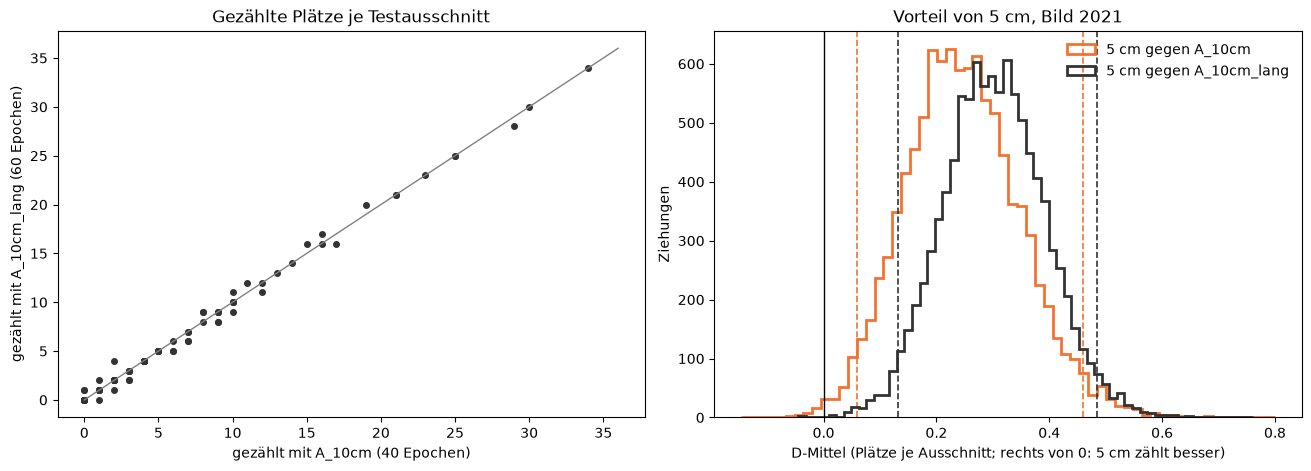

In [19]:
# Abbildung: links gezählte Plätze je Testausschnitt, erster gegen länger gelernten Lauf; rechts die Bootstrap-Verteilungen von D-Mittel
FARBE = {ERST: "#f47230", LANG: "#333333"}                           # erster Lauf orange (Projektfarbe 10 cm), länger gelernter Lauf dunkelgrau
fig, achsen = plt.subplots(1, 2, figsize=(13, 4.6), layout="constrained")
grenze = max(erst.gezaehlt.max(), lang.gezaehlt.max()) + 2
achsen[0].scatter(erst.gezaehlt, lang.gezaehlt, s=16, color=FARBE[LANG])
achsen[0].plot([0, grenze], [0, grenze], color="grey", linewidth=1)  # Diagonale: beide Netze zählen gleich viel
achsen[0].set_xlabel("gezählt mit A_10cm (40 Epochen)"); achsen[0].set_ylabel("gezählt mit A_10cm_lang (60 Epochen)")
achsen[0].set_title("Gezählte Plätze je Testausschnitt")
for lauf in [ERST, LANG]:
    achsen[1].hist(verteilungen[lauf], bins=60, histtype="step", linewidth=2, color=FARBE[lauf], label=f"5 cm gegen {lauf}")
    for rand in [leitfrage.intervall_unten[lauf], leitfrage.intervall_oben[lauf]]:
        achsen[1].axvline(rand, color=FARBE[lauf], linestyle="--", linewidth=1.2)   # Grenzen des 95-%-Intervalls
achsen[1].axvline(0, color="black", linewidth=1)                     # kein Unterschied
achsen[1].set_xlabel("D-Mittel (Plätze je Ausschnitt; rechts von 0: 5 cm zählt besser)"); achsen[1].set_ylabel("Ziehungen")
achsen[1].set_title("Vorteil von 5 cm, Bild 2021")
achsen[1].legend(frameon=False)
fig.savefig(ABB / "11_nachtrag.png", dpi=130, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Links: Jeder Punkt ist ein Testausschnitt. Auf der grauen Linie zählen beide 10-cm-Netze gleich viel; je weiter ein Punkt davon entfernt liegt, desto stärker unterscheiden sie sich an dieser Stelle. Rechts: die Bootstrap-Verteilung von $\bar D$ für beide Vergleiche, orange mit dem ersten und dunkelgrau mit dem länger gelernten 10-cm-Netz. Die gestrichelten Linien sind die Grenzen der 95-%-Intervalle, die schwarze Linie steht bei 0. Liegt ein Intervall ganz rechts von 0, zählt 5 cm in diesem Vergleich besser.

## 5. Was die Gegenprobe zeigt

Die folgende Zelle schreibt das Ergebnis in Sätzen. Jede Zahl stammt aus den Tabellen oben. Der Schluss folgt der Regel, die vor dem Rechnen festgelegt wurde (`01b`, Abschnitt 11.2, N2).

In [20]:
e, l = auswertung.loc[ERST], auswertung.loc[LANG]
print(f"Lernen: {ERST} {int(e.epochen)} Epochen, beste Epoche {int(e.beste_epoche)}, Schwelle {e.schwelle} | {LANG} {int(l.epochen)} Epochen, beste Epoche {int(l.beste_epoche)}, Schwelle {l.schwelle}.")
print(f"1. Fläche: IoU {e.iou:.3f} (erster Lauf) und {l.iou:.3f} (länger gelernt). Gemeldete ÷ wahre Fläche: {e.flaechenverhaeltnis:.2f} und {l.flaechenverhaeltnis:.2f}.")
print(f"2. Anzahl: gezählt {int(e.gezaehlt)} und {int(l.gezaehlt)} von {int(e.wahr)} sichtbaren Feldern ({e.bias:+.0%} und {l.bias:+.0%}). MAE je Ausschnitt {e.mae:.2f} und {l.mae:.2f} Plätze; bei 5 cm {uebersicht.mae[FEIN]:.2f}.")
print(f"3. 5 cm gegen 10 cm: Vorteil von 5 cm {e.D_mittel:+.2f} Plätze je Ausschnitt (95-%-Intervall {e.intervall_unten:+.2f} bis {e.intervall_oben:+.2f}) mit dem ersten Netz, "
      f"{l.D_mittel:+.2f} ({l.intervall_unten:+.2f} bis {l.intervall_oben:+.2f}) mit dem länger gelernten.")
print(f"4. Delta zu amtlich: {int(e.delta):+d} Plätze ({e['delta_in_%_von_amtlich']:+.1f} %) und {int(l.delta):+d} Plätze ({l['delta_in_%_von_amtlich']:+.1f} %, 95-%-Intervall {l['intervall_unten_%']:+.1f} bis {l['intervall_oben_%']:+.1f} %). "
      f"Teil 1, Fehler der Methode: {int(e.teil_1_fehler_der_methode):+d} und {int(l.teil_1_fehler_der_methode):+d}.")
print()
if l.intervall_ohne_null and l.D_mittel > 0:
    print("Schluss nach der Regel: Die Aussage '5 cm zählt im Bild 2021 besser als 10 cm' ist bestätigt. Das Intervall enthält die 0 auch mit dem länger gelernten Netz nicht.")
else:
    print("Schluss nach der Regel: Die Aussage '5 cm zählt im Bild 2021 besser als 10 cm' hängt von der Lerndauer ab. Mit dem länger gelernten Netz enthält das Intervall die 0.")

Lernen: A_10cm 40 Epochen, beste Epoche 40, Schwelle 0.4 | A_10cm_lang 60 Epochen, beste Epoche 55, Schwelle 0.4.
1. Fläche: IoU 0.582 (erster Lauf) und 0.583 (länger gelernt). Gemeldete ÷ wahre Fläche: 0.91 und 0.90.
2. Anzahl: gezählt 626 und 624 von 708 sichtbaren Feldern (-12% und -12%). MAE je Ausschnitt 1.11 und 1.17 Plätze; bei 5 cm 0.86.
3. 5 cm gegen 10 cm: Vorteil von 5 cm +0.25 Plätze je Ausschnitt (95-%-Intervall +0.06 bis +0.46) mit dem ersten Netz, +0.31 (+0.13 bis +0.48) mit dem länger gelernten.
4. Delta zu amtlich: -18 Plätze (-5.1 %) und -14 Plätze (-4.0 %, 95-%-Intervall -14.3 bis +4.7 %). Teil 1, Fehler der Methode: -24 und -20.

Schluss nach der Regel: Die Aussage '5 cm zählt im Bild 2021 besser als 10 cm' ist bestätigt. Das Intervall enthält die 0 auch mit dem länger gelernten Netz nicht.


## Grenzen dieser Gegenprobe

| Grenze | Folge |
| --- | --- |
| **Zweite Auswertung derselben Testblöcke.** | Die Gegenprobe wurde beschlossen, als die Ergebnisse der ersten Auswertung bekannt waren. Darum bleibt die erste Auswertung das Ergebnis. Die Gegenprobe zeigt nur, ob es an der Lerndauer hängt. |
| **Zwei Dinge ändern sich zugleich.** | Der längere Lauf ist ein neuer Lernlauf. Auf der Grafikkarte läuft er nicht genau gleich ab wie der erste (Notebook 07, Abschnitt 11). Ein Unterschied zwischen den beiden 10-cm-Netzen kann von der Lerndauer kommen oder vom Zufall eines zweiten Lernlaufs. Mit einem einzigen Lauf lässt sich das nicht trennen. |
| **Ein Paar ist kein Mass für den Zufall.** | Die zwei 10-cm-Netze geben einen ersten Eindruck, wie stark Ergebnisse von Lernlauf zu Lernlauf schwanken. Für eine Zahl dazu bräuchte es mehrere Wiederholungen, auch beim 5-cm-Netz. |
| **Nur ein Lauf wurde wiederholt.** | Bei den anderen drei Läufen lag die beste Epoche nicht am Ende; sie wurden nicht wiederholt. Für das Bild 2024/25 gibt es keine Gegenprobe. |
| **Alle Grenzen aus Notebook 10 gelten weiter.** | Zum Beispiel: 15 Testblöcke, Ground Truth aus einem Durchgang einer Person, das 10-cm-Bild ist gerechnet. |

## Was wir gesehen haben

Stand der Ausführung vom 27.11.2026:

- **Die Schritte sind dieselben wie in den Notebooks 08 bis 10.** Alle drei Kontrollen gehen auf: Die Vorhersage des ersten Netzes ist neu gerechnet Pixel für Pixel gleich wie die gespeicherte, die Zählung stimmt in jedem Testausschnitt, und die Kennzahlen stimmen mit Notebook 10 überein. Damit ist auch gezeigt, dass sich Vorhersage und Zählung wiederholen lassen.
- **Das länger gelernte 10-cm-Netz ist in den Testblöcken nicht besser als das erste.** Fläche und Anzahl liegen nahe beieinander (Abschnitt 4, Schritt 1); der Zählfehler je Ausschnitt ist etwas grösser.
- **Die Antwort auf die Leitfrage hält.** Auch gegen das länger gelernte 10-cm-Netz zählt 5 cm im Bild 2021 besser, und das Intervall enthält die 0 nicht (Abschnitt 4, Schritt 2, und Abschnitt 5).
- **Zwei Lernläufe geben nicht genau dasselbe Ergebnis.** Die beiden 10-cm-Netze unterscheiden sich leicht in MAE und Delta (Abschnitt 4). Ob das von der Lerndauer kommt oder vom Zufall eines zweiten Lernlaufs, lässt sich nicht trennen.

## Wie es weitergeht

Die erste Auswertung bleibt das Ergebnis des Pilots. Die Gegenprobe steht daneben, auch in der README und im Protokoll (`ml_pipeline/PIPELINE.md`). An Netz, Schwelle und Zählformel wird nichts geändert.